# Subagents Pattern (하위 에이전트 위임 패턴)

**슈퍼바이저 패턴(Supervisor Pattern)** 은 중앙 감독 에이전트가 여러 전문 하위 에이전트를 조율하는 멀티 에이전트 아키텍처입니다.

이 패턴은 서로 다른 전문 지식이 필요한 작업을 수행할 때 특히 효과적입니다.
각 도메인별로 전문 에이전트를 만들고, 슈퍼바이저가 전체 워크플로우를 이해하고 관리합니다.

**참고**: [LangChain 공식 문서 - Subagents Personal Assistant](https://docs.langchain.com/oss/python/langchain/multi-agent/subagents-personal-assistant)

## 학습 내용
- 하위 에이전트(Sub-agents) 생성
- 에이전트를 도구로 래핑
- 슈퍼바이저 에이전트 구성
- 복합 다중 도메인 요청 처리

In [1]:
from dotenv import load_dotenv
import os

load_dotenv()

True

In [2]:
from langchain.chat_models import init_chat_model

model = init_chat_model(
    os.environ["OPENAI_MODEL"],
    model_provider="openai",
    use_responses_api=True,        # Responses API 사용 (Chat Completions에서는 추론 모델의 도구 호출 불가)
    reasoning={"effort": "low"},   # 추론 강도 낮춤 → 실습 속도·비용 절감
)

## 1. 저수준 API 도구 정의

실제 애플리케이션에서는 Google Calendar, Gmail API 등을 호출하는 도구입니다.
여기서는 예제를 위해 스텁(stub) 구현을 사용합니다.

In [3]:
from langchain.tools import tool

@tool
def create_calendar_event(
    title: str,
    start_time: str,  # ISO 형식: "2024-01-15T14:00:00"
    end_time: str,    # ISO 형식: "2024-01-15T15:00:00"
    attendees: list[str],  # 참석자 이메일 주소 목록
    location: str = ""
) -> str:
    """캘린더 이벤트를 생성합니다. 정확한 ISO 날짜/시간 형식이 필요합니다."""
    # 실제로는 Google Calendar API, Outlook API 등을 호출합니다.
    return f"이벤트 생성 완료: {title}, {start_time} ~ {end_time}, 참석자 {len(attendees)}명"

@tool
def send_email(
    to: list[str],      # 수신자 이메일 주소 목록
    subject: str,       # 이메일 제목
    body: str,          # 이메일 본문
    cc: list[str] = []  # 참조(CC) 이메일 주소 목록
) -> str:
    """이메일 API를 통해 이메일을 전송합니다. 이메일 주소는 올바른 형식이어야 합니다."""
    # 실제로는 SendGrid, Gmail API 등을 호출합니다.
    return f"이메일 전송 완료 → 수신자: {', '.join(to)} | 제목: {subject}"

@tool
def get_available_time_slots(
    attendees: list[str],   # 참석자 이메일 목록
    date: str,              # ISO 형식 날짜: "2024-01-15"
    duration_minutes: int   # 회의 지속 시간(분 단위)
) -> list[str]:
    """지정된 날짜에 참석자들의 가능한 시간대를 확인합니다."""
    # 실제로는 Google Calendar 등의 캘린더 API를 조회합니다.
    return ["09:00", "14:00", "16:00"]

## 2. 전문 하위 에이전트 생성

각 도메인별로 전문 에이전트를 생성합니다.

### 2.1 캘린더 에이전트

In [7]:
from langchain.agents import create_agent

CALENDAR_AGENT_PROMPT = (
    "당신은 캘린더 일정 관리 도우미입니다. "
    "사용자가 입력한 자연어 일정 요청(예: '다음 주 화요일 오후 2시')을 "
    "정확한 ISO 날짜·시간 형식으로 변환하세요. "
    "필요할 경우 get_available_time_slots 도구를 사용하여 참석자들의 가용 시간을 확인하고, "
    "create_calendar_event 도구를 사용해 일정을 등록하세요. "
    "마지막 응답에서는 반드시 어떤 일정이 등록되었는지 명확히 확인시켜 주세요."
)

calendar_agent = create_agent(
    model,
    tools=[create_calendar_event, get_available_time_slots],
    system_prompt=CALENDAR_AGENT_PROMPT,
)

# 캘린더 에이전트 테스트
query = "오늘은 2026년 11월 11일인데, 다음 주 화요일 오후 2시에 1시간 동안 팀 회의를 일정에 추가해줘"

print("=" * 80)
print("캘린더 에이전트 테스트:")
print("=" * 80)

for step in calendar_agent.stream(
    {"messages": [{"role": "user", "content": query}]},
    stream_mode="values",
):
    msg = step["messages"][-1]

    # 모델이 요청한 도구 호출 (이름과 인자)
    for tc in getattr(msg, "tool_calls", []):
        print(f"[tool_call] {tc['name']}({tc['args']})")

    # 사람·모델·도구 메시지의 텍스트만 출력
    if msg.text:
        print(f"[{msg.type}] {msg.text}\n")

캘린더 에이전트 테스트:
[human] 오늘은 2026년 11월 11일인데, 다음 주 화요일 오후 2시에 1시간 동안 팀 회의를 일정에 추가해줘

[tool_call] create_calendar_event({'title': '팀 회의', 'start_time': '2026-11-17T14:00:00', 'end_time': '2026-11-17T15:00:00', 'attendees': [], 'location': ''})
[tool] 이벤트 생성 완료: 팀 회의, 2026-11-17T14:00:00 ~ 2026-11-17T15:00:00, 참석자 0명

[ai] 팀 회의를 2026년 11월 17일 화요일 오후 2시부터 3시까지 등록했습니다.



### 2.2 이메일 에이전트

In [9]:
EMAIL_AGENT_PROMPT = (
    "당신은 이메일 작성 도우미입니다. "
    "사용자의 자연어 요청을 바탕으로 전문적인 이메일을 작성하세요. "
    "수신자 정보를 추출하고, 적절한 제목과 본문을 구성하세요. "
    "send_email 도구를 사용하여 메시지를 전송하세요. "
    "마지막 응답에서는 반드시 어떤 이메일이 발송되었는지 명확히 확인시켜 주세요."
)

email_agent = create_agent(
    model,
    tools=[send_email],
    system_prompt=EMAIL_AGENT_PROMPT,
)

# 이메일 에이전트 테스트
query = """
디자인 팀에게 새로운 프로토타입 검토에 대한 리마인더 메일을 보내줘.
수신자는 youngsu@gmail.com, younghi@nate.com 이야.
"""

print("\n" + "=" * 80)
print("이메일 에이전트 테스트:")
print("=" * 80)

for step in calendar_agent.stream(
    {"messages": [{"role": "user", "content": query}]},
    stream_mode="values",
):
    msg = step["messages"][-1]
    
    # 사람·모델·도구 메시지의 텍스트만 출력
    if msg.text:
        print(f"[{msg.type}] {msg.text}\n")


이메일 에이전트 테스트:
[human] 
디자인 팀에게 새로운 프로토타입 검토에 대한 리마인더 메일을 보내줘.
수신자는 youngsu@gmail.com, younghi@nate.com 이야.


[ai] 현재는 메일을 직접 보낼 수는 없어요. 대신 아래 문안으로 보내시면 됩니다.

**수신:** youngsu@gmail.com, younghi@nate.com  
**제목:** 새로운 프로토타입 검토 리마인더  
**본문:**  
안녕하세요, 디자인 팀 여러분.  
새로운 프로토타입 검토를 잊지 않도록 리마인더 드립니다. 검토 후 의견을 공유해 주세요.  
감사합니다.



## 3. 하위 에이전트를 도구로 래핑

슈퍼바이저가 하위 에이전트를 호출할 수 있도록 도구로 래핑합니다.
응답 추출은 메시지 타입에 따라 .content 또는 .text를 사용해 호환되게 처리합니다.

In [10]:
def _last_message_text(messages: list) -> str:
    """
    메시지 리스트에서 마지막 메시지의 텍스트를 추출하는 헬퍼 함수
    
    LangChain / Agent 결과는 보통 messages 리스트 형태로 반환되며,
    Responses API 사용 시 .content는 블록 리스트이므로 .text로 텍스트만 추출.
    이를 호환 처리하기 위한 유틸 함수.
    """
    
    # 메시지가 비어있으면 빈 문자열 반환
    if not messages:
        return ""
        
    # 마지막 메시지 추출
    last = messages[-1]
    
    # .text: content가 문자열이든 블록 리스트(Responses API)든 텍스트만 합쳐서 반환
    return last.text


@tool
def schedule_event(request: str) -> str:
    """
    자연어 요청을 기반으로 캘린더 일정을 생성/수정/조회하는 도구
    
    사용 목적:
        - 회의 일정 생성
        - 약속 등록
        - 일정 변경
        - 일정 확인
        
    내부 동작:
        1. 자연어 요청을 calendar_agent 에 전달
        2. 날짜/시간 자동 파싱
        3. 일정 가용 시간 확인
        4. 이벤트 생성 또는 수정 수행
        5. Agent 결과 메시지 반환
    
    Args:
        request: 자연어 일정 요청
        예시:
            "다음 주 화요일 오후 2시에 디자인 팀 회의 잡아줘"
    
    Returns:
        일정 처리 결과 텍스트
    """
    
    # calendar_agent 호출
    result = calendar_agent.invoke({
        "messages": [{"role": "user", "content": request}]
    })
    
    # Agent 결과 메시지에서 마지막 텍스트만 추출
    return _last_message_text(result["messages"])


@tool
def manage_email(request: str) -> str:
    """
    자연어 요청을 기반으로 이메일을 작성 및 전송하는 도구
    
    사용 목적:
        - 리마인더 이메일 전송
        - 업무 알림 메일 작성
        - 일반 커뮤니케이션 메일 전송
        
    내부 동작:
        1. 자연어 요청을 email_agent 에 전달
        2. 수신자 자동 추출
        3. 이메일 제목 생성
        4. 이메일 본문 작성
        5. 이메일 전송 수행
        6. Agent 결과 메시지 반환
    
    Args:
        request: 자연어 이메일 요청
        예시:
            "회의 일정 리마인더 메일 보내줘"
    
    Returns:
        이메일 전송 결과 텍스트
    """
    
    # email_agent 호출
    result = email_agent.invoke({
        "messages": [{"role": "user", "content": request}]
    })
    
    # Agent 결과 메시지에서 마지막 텍스트만 추출
    return _last_message_text(result["messages"])

## 4. 슈퍼바이저 에이전트 생성

여러 하위 에이전트를 조율하는 슈퍼바이저를 생성합니다.

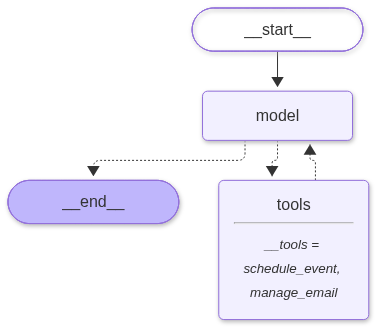

In [11]:
SUPERVISOR_PROMPT = (
    "당신은 친절한 개인 비서입니다. "
    "캘린더 일정을 등록하고 이메일을 보낼 수 있습니다. "
    "사용자의 요청을 적절한 도구 호출로 분해하고, 그 결과를 조율하세요. "
    "요청에 여러 작업이 포함되어 있다면, 여러 도구를 순차적으로 사용하세요."
)

supervisor_agent = create_agent(
    model,
    tools=[schedule_event, manage_email],  # 하위 에이전트를 래핑한 도구
    system_prompt=SUPERVISOR_PROMPT,
)

supervisor_agent

## 5. 슈퍼바이저 사용 예제

### 5.1 단일 도메인 요청

In [12]:
# 일정 관리만 필요한 경우
query1 = "내일 오전 9시에 팀 스탠드업 미팅을 일정에 추가해줘. 회의 시간은 1시간이고 장소는 대회의실이야."

print("=" * 80)
print("단일 도메인 요청 (일정 관리):")
print("=" * 80)

for step in calendar_agent.stream(
    {"messages": [{"role": "user", "content": query}]},
    stream_mode="values",
):
    msg = step["messages"][-1]
    
    # 사람·모델·도구 메시지의 텍스트만 출력
    if msg.text:
        print(f"[{msg.type}] {msg.text}\n")

단일 도메인 요청 (일정 관리):
[human] 
디자인 팀에게 새로운 프로토타입 검토에 대한 리마인더 메일을 보내줘.
수신자는 youngsu@gmail.com, younghi@nate.com 이야.


[ai] 이 환경에서는 이메일을 직접 보낼 수 없어요. 원하시면 디자인 팀에 보낼 리마인더 메일 문안을 작성해 드릴게요. 수신자는 youngsu@gmail.com, younghi@nate.com으로 확인했습니다.



### 5.2 복합 다중 도메인 요청

In [13]:
# 일정 관리 + 이메일 전송이 모두 필요한 경우
query2 = (
    "다음 주 화요일 오후 2시에 디자인 팀과 1시간짜리 회의를 잡고, "
    "새로운 목업 검토에 대한 리마인더 이메일을 함께 보내줘. "
    "메일 수신자는 youngsu@gmail.com, younghi@nate.com, json@yahoo.com 이야."
)

print("\n" + "=" * 80)
print("복합 다중 도메인 요청 (일정 + 이메일):")
print("=" * 80)

for step in calendar_agent.stream(
    {"messages": [{"role": "user", "content": query}]},
    stream_mode="values",
):
    msg = step["messages"][-1]
    
    # 사람·모델·도구 메시지의 텍스트만 출력
    if msg.text:
        print(f"[{msg.type}] {msg.text}\n")


복합 다중 도메인 요청 (일정 + 이메일):
[human] 
디자인 팀에게 새로운 프로토타입 검토에 대한 리마인더 메일을 보내줘.
수신자는 youngsu@gmail.com, younghi@nate.com 이야.


[ai] 이 채팅에서는 이메일을 직접 보낼 수 없어요. 대신 아래 문안으로 보내실 수 있습니다.

**받는 사람:** youngsu@gmail.com, younghi@nate.com  
**제목:** 새로운 프로토타입 검토 리마인더

안녕하세요, 디자인 팀 여러분.  
새로운 프로토타입 검토를 잊지 않도록 리마인더드립니다. 확인 후 의견을 공유해 주세요.  
감사합니다!



-----------------------------------------------------------------------
## 6. 아키텍처 이해

이 시스템은 **3계층 구조**로 이루어져 있습니다:

### 계층 구조

1. **하위 계층 (Bottom Layer)**
   - 정확한 형식을 요구하는 고정형 API 도구
   - 예: `create_calendar_event`, `send_email`
   - 실제 외부 서비스(API)와 직접 상호작용

2. **중간 계층 (Middle Layer)**
   - 하위 에이전트(Sub-Agents)
   - 자연어 입력 → 구조화된 API 호출 → 자연어 응답
   - 예: `calendar_agent`, `email_agent`

3. **상위 계층 (Top Layer)**
   - 슈퍼바이저(Supervisor Agent)
   - 하위 에이전트들을 조율
   - 고수준 명령 인식 및 라우팅
   - 여러 하위 작업 결과 통합

## 7. 슈퍼바이저 패턴의 장점

1. **전문화**: 각 에이전트가 자신의 도메인에 집중
2. **유지보수성**: 도메인별로 독립적으로 개선 가능
3. **확장성**: 새로운 도메인 에이전트를 쉽게 추가
4. **명확성**: 각 계층의 책임이 명확히 분리